
## This notebook explores the synthetic financial transaction dataset (v2.0).

The objective is to understand transaction distributions, customer financial behaviour, income and expenditure patterns, category-level spending, merchant activity, and temporal trends.

The analysis uses the enriched dataset generated by the ingestion and preprocessing pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/enriched_transactions.csv")

df["date"] = pd.to_datetime(df["date"])

df.head()

,transaction_id,customer_id,date,description,amount,category,transaction_type,merchant,currency,validation_issues,year,month,day_of_week,is_weekend
0,TXN0000001,CUST0063,2025-01-03,AMAZON PAYMENT,-2621.22,Shopping,debit,Amazon,INR,NaN,2025,1,Friday,False
1,TXN0000002,CUST0134,2025-06-13,ZOMATO PAYMENT,-362.04,Food & Dining,debit,Zomato,INR,NaN,2025,6,Friday,False
2,TXN0000003,CUST0167,2025-04-07,RENT PAYMENT,-4519.96,Housing,debit,Landlord Transfer,INR,NaN,2025,4,Monday,False
3,TXN0000004,CUST0115,2025-12-05,ZOMATO PAYMENT,-279.12,Food & Dining,debit,Zomato,INR,NaN,2025,12,Friday,False
4,TXN0000005,CUST0104,2025-05-08,LOCAL RETAIL STORE PAYMENT,-1458.84,Shopping,debit,Local Retail Store,INR,NaN,2025,5,Thursday,False


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (56421, 14)

Columns:
['transaction_id', 'customer_id', 'date', 'description', 'amount', 'category', 'transaction_type', 'merchant', 'currency', 'validation_issues', 'year', 'month', 'day_of_week', 'is_weekend']

Data Types:
transaction_id                  str
customer_id                     str
date                 datetime64[us]
description                     str
amount                      float64
category                        str
transaction_type                str
merchant                        str
currency                        str
validation_issues           float64
year                          int64
month                         int64
day_of_week                     str
is_weekend                     bool
dtype: object

Statistical Summary:


,date,amount,validation_issues,year,month
count,56421,56421.000000,0.0,56421.0,56421.000000
mean,2025-07-01 07:43:29.219971,1174.434827,NaN,2025.0,6.547863
min,2025-01-01 00:00:00,-139633.290000,NaN,2025.0,1.000000
25%,2025-04-01 00:00:00,-1996.350000,NaN,2025.0,4.000000
50%,2025-07-02 00:00:00,-941.390000,NaN,2025.0,7.000000
75%,2025-10-03 00:00:00,-449.480000,NaN,2025.0,10.000000
max,2025-12-31 00:00:00,815640.570000,NaN,2025.0,12.000000
std,NaN,22745.320307,NaN,0.0,3.468683


In [3]:
print("Unique Customers:", df["customer_id"].nunique())
print("Unique Transactions:", df["transaction_id"].nunique())
print("Unique Categories:", df["category"].nunique())
print("Unique Merchants:", df["merchant"].nunique())
print("Unique Currencies:", df["currency"].unique())

Unique Customers: 180
Unique Transactions: 56421
Unique Categories: 13
Unique Merchants: 31
Unique Currencies: <ArrowStringArray>
['INR']
Length: 1, dtype: str


In [4]:
print("Duplicate Transaction IDs:", df["transaction_id"].duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTransaction Type Distribution:")
print(df["transaction_type"].value_counts())

Duplicate Transaction IDs: 0

Missing Values:
transaction_id           0
customer_id              0
date                     0
description              0
amount                   0
category                 0
transaction_type         0
merchant                 0
currency                 0
validation_issues    56421
year                     0
month                    0
day_of_week              0
is_weekend               0
dtype: int64

Transaction Type Distribution:
transaction_type
debit     53274
credit     3147
Name: count, dtype: int64


### Validation_issues if none gives a "NaN" value, hence duplicate can be ignored for now.


In [5]:
df.groupby("transaction_type")["amount"].agg(["count", "min", "max", "mean"])

,count,min,max,mean
transaction_type,,,,
credit,3147,29.29,815640.57,59635.264382
debit,53274,-139633.29,-22.85,-2278.961400


In [6]:
credit_transactions = df.loc[df["transaction_type"] == "credit"]
debit_transactions = df.loc[df["transaction_type"] == "debit"]

print("Total Transactions:", len(df))
print("Credit Transactions:", len(credit_transactions))
print("Debit Transactions:", len(debit_transactions))

print("\nCredit Percentage:", round(len(credit_transactions) / len(df) * 100, 2))
print("Debit Percentage:", round(len(debit_transactions) / len(df) * 100, 2))

Total Transactions: 56421
Credit Transactions: 3147
Debit Transactions: 53274

Credit Percentage: 5.58
Debit Percentage: 94.42


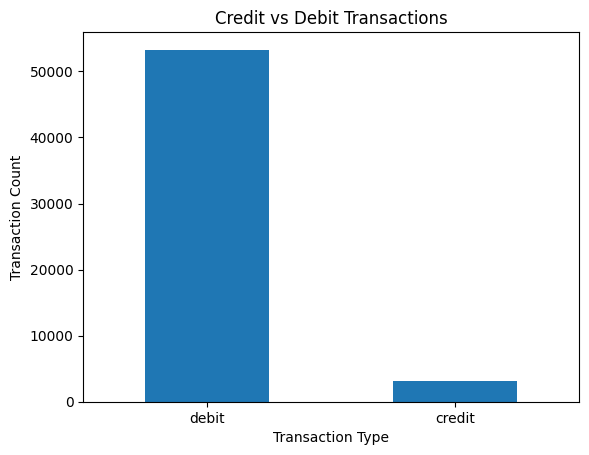

In [7]:
transaction_counts = df["transaction_type"].value_counts()

transaction_counts.plot(kind="bar", title="Credit vs Debit Transactions", ylabel="Transaction Count", xlabel="Transaction Type", rot=0)
plt.show()

In [8]:
df["amount_magnitude"] = df["amount"].abs()

print("Overall Transaction Amount Statistics:")
print(df["amount_magnitude"].describe())

print("\nCredit Amount Statistics:")
print(credit_transactions["amount"].describe())

print("\nDebit Amount Statistics:")
print(debit_transactions["amount"].abs().describe())

Overall Transaction Amount Statistics:
count     56421.000000
mean       5478.129892
std       22106.978049
min          22.850000
25%         521.190000
50%        1074.900000
75%        2294.980000
max      815640.570000
Name: amount_magnitude, dtype: float64

Credit Amount Statistics:
count      3147.000000
mean      59635.264382
std       72701.773545
min          29.290000
25%       12466.585000
50%       38793.770000
75%       89759.750000
max      815640.570000
Name: amount, dtype: float64

Debit Amount Statistics:
count     53274.000000
mean       2278.961400
std        4685.968781
min          22.850000
25%         515.342500
50%        1025.235000
75%        2084.662500
max      139633.290000
Name: amount, dtype: float64


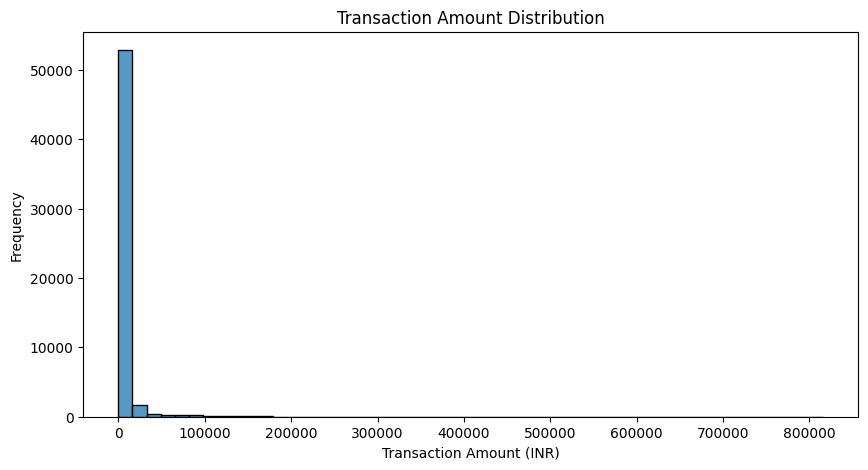

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="amount_magnitude", bins=50)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")
plt.show()

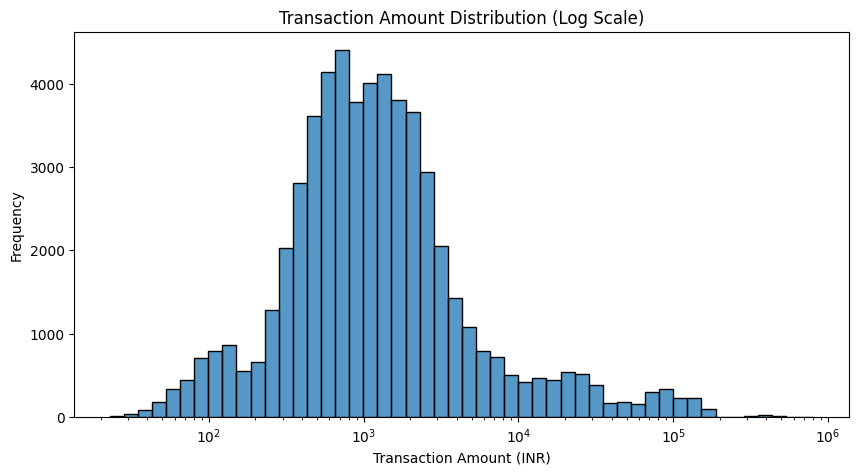

In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="amount_magnitude", bins=50, log_scale=True)
plt.title("Transaction Amount Distribution (Log Scale)")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")
plt.show()

In [11]:
df.nlargest(10, "amount_magnitude")[["transaction_id", "customer_id", "date", "description", "amount", "category", "transaction_type"]]

,transaction_id,customer_id,date,description,amount,category,transaction_type
52246,TXN0052247,CUST0068,2025-09-01,SALARY CREDIT EMPLOYER PAYROLL,815640.57,Income,credit
39516,TXN0039517,CUST0049,2025-03-09,SALARY CREDIT EMPLOYER PAYROLL,793612.69,Income,credit
38871,TXN0038872,CUST0005,2025-06-02,SALARY CREDIT EMPLOYER PAYROLL,723749.34,Income,credit
31356,TXN0031357,CUST0171,2025-06-21,REFUND RECEIVED,665507.71,Income,credit
12726,TXN0012727,CUST0004,2025-05-06,INTEREST CREDIT,639069.34,Income,credit
3938,TXN0003939,CUST0075,2025-05-01,SALARY CREDIT EMPLOYER PAYROLL,628359.30,Income,credit
8167,TXN0008168,CUST0030,2025-05-28,INTEREST CREDIT,626947.80,Income,credit
37694,TXN0037695,CUST0042,2025-01-06,SALARY CREDIT EMPLOYER PAYROLL,586682.78,Income,credit
42589,TXN0042590,CUST0150,2025-11-01,SALARY CREDIT EMPLOYER PAYROLL,577654.31,Income,credit
39154,TXN0039155,CUST0110,2025-08-27,REFUND RECEIVED,567013.78,Income,credit


In [12]:
category_spending = debit_transactions.groupby("category")["amount"].sum().abs().sort_values(ascending=False)

category_spending

category
Housing              39087353.30
Groceries            19560289.54
Education            11106930.68
Investment           10986449.97
Travel                9672171.35
Shopping              8826091.35
Bills & Utilities     5660351.74
Transport             5234045.56
Food & Dining         4873511.40
Healthcare            3351986.03
Personal Care         1832170.98
Entertainment         1218037.74
Name: amount, dtype: float64

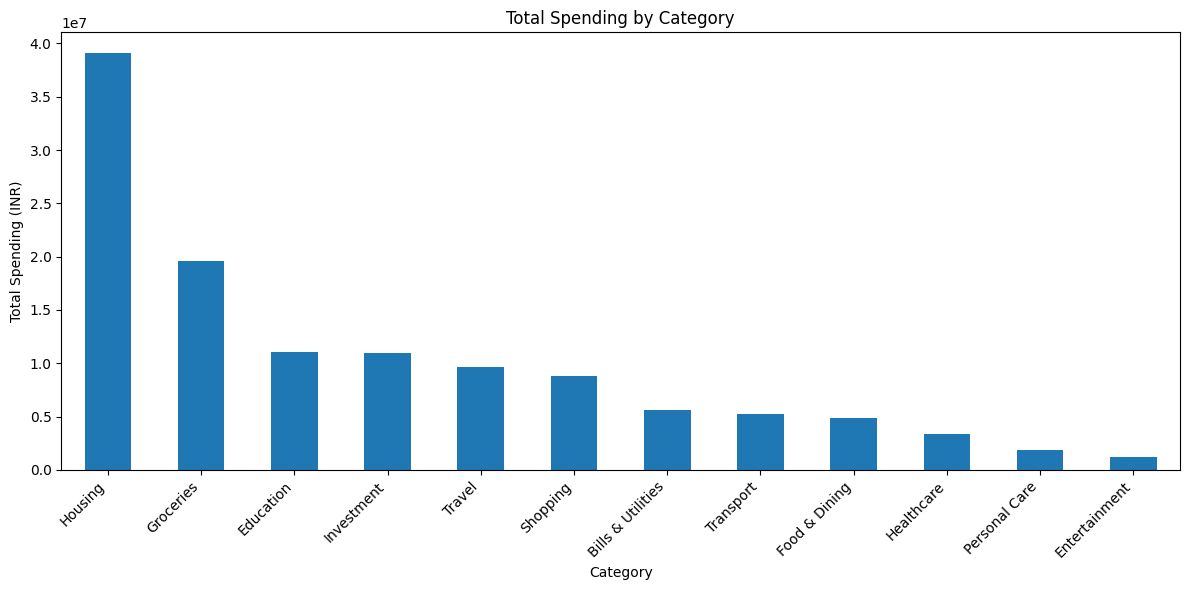

In [13]:
plt.figure(figsize=(12, 6))
category_spending.plot(kind="bar")
plt.title("Total Spending by Category")
plt.xlabel("Category")
plt.ylabel("Total Spending (INR)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
category_counts = debit_transactions["category"].value_counts()

category_counts

category
Groceries            10051
Food & Dining         8231
Transport             7392
Shopping              5462
Bills & Utilities     4320
Healthcare            3635
Entertainment         3135
Education             2748
Personal Care         2581
Travel                2359
Housing               1764
Investment            1596
Name: count, dtype: int64

In [15]:
category_analysis = debit_transactions.groupby("category").agg(transaction_count=("transaction_id", "count"), total_spending=("amount", lambda x: x.abs().sum()), average_spending=("amount", lambda x: x.abs().mean())).sort_values("total_spending", ascending=False)

category_analysis

,transaction_count,total_spending,average_spending
category,,,
Housing,1764,39087353.30,22158.363549
Groceries,10051,19560289.54,1946.103824
Education,2748,11106930.68,4041.823392
Investment,1596,10986449.97,6883.740583
Travel,2359,9672171.35,4100.115028
Shopping,5462,8826091.35,1615.908339
Bills & Utilities,4320,5660351.74,1310.266606
Transport,7392,5234045.56,708.068934
Food & Dining,8231,4873511.40,592.092261


In [16]:
monthly_inflow = credit_transactions.groupby(df["date"].dt.to_period("M"))["amount"].sum()
monthly_outflow = debit_transactions.groupby(df["date"].dt.to_period("M"))["amount"].sum().abs()

monthly_financial_summary = pd.DataFrame({"total_inflow": monthly_inflow, "total_outflow": monthly_outflow})

monthly_financial_summary["net_cash_flow"] = monthly_financial_summary["total_inflow"] - monthly_financial_summary["total_outflow"]

monthly_financial_summary

,total_inflow,total_outflow,net_cash_flow
date,,,
2025-01,51679266.81,6963905.93,44715360.88
2025-02,27349745.20,6734619.55,20615125.65
2025-03,27491192.52,12140773.09,15350419.43
2025-04,28504808.91,11592812.91,16911996.00
2025-05,8807128.27,12698017.90,-3890889.63
2025-06,5904863.80,13421542.55,-7516678.75
2025-07,5932342.46,14963712.98,-9031370.52
2025-08,5861294.38,9155937.79,-3294643.41
2025-09,6803063.35,9005398.69,-2202335.34


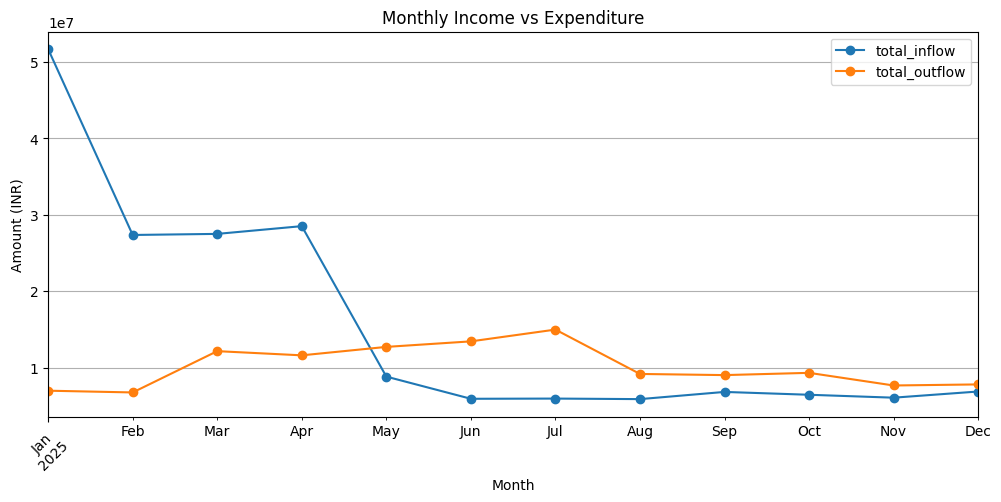

In [17]:
monthly_financial_summary[["total_inflow", "total_outflow"]].plot(kind="line", figsize=(12, 5), marker="o", title="Monthly Income vs Expenditure")
plt.xlabel("Month")
plt.ylabel("Amount (INR)")
plt.xticks(rotation=45)
plt.grid()
plt.show()

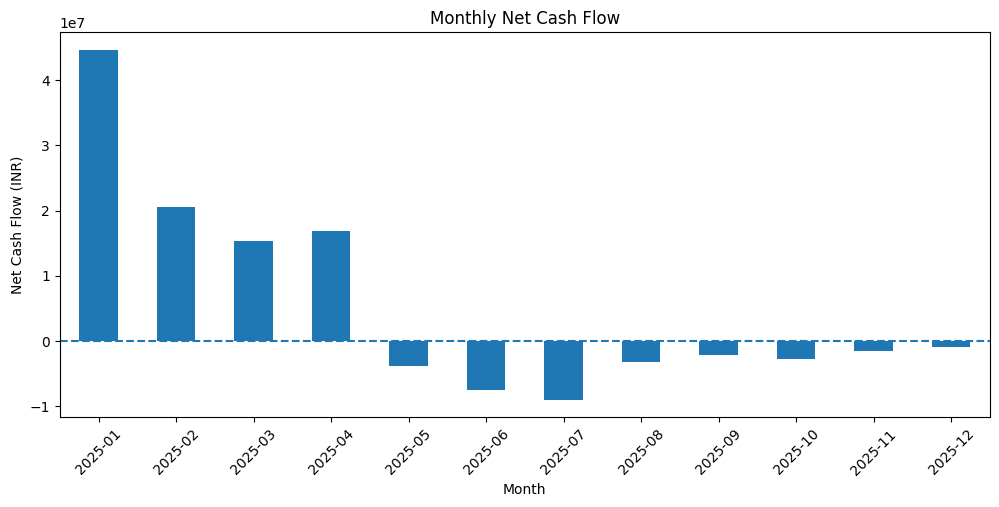

In [18]:
monthly_financial_summary["net_cash_flow"].plot(kind="bar", figsize=(12, 5), title="Monthly Net Cash Flow")
plt.axhline(y=0, linestyle="--")
plt.xlabel("Month")
plt.ylabel("Net Cash Flow (INR)")
plt.xticks(rotation=45)
plt.show()

In [19]:
total_inflow = credit_transactions.groupby("customer_id")["amount"].sum().rename("total_inflow")
total_outflow = debit_transactions.groupby("customer_id")["amount"].sum().abs().rename("total_outflow")

customer_financial_summary = pd.concat([total_inflow, total_outflow], axis=1).fillna(0)

customer_financial_summary["net_cash_flow"] = customer_financial_summary["total_inflow"] - customer_financial_summary["total_outflow"]

customer_financial_summary["transaction_count"] = df.groupby("customer_id")["transaction_id"].count()

customer_financial_summary["average_transaction_amount"] = df.groupby("customer_id")["amount_magnitude"].mean()

customer_financial_summary.head()

,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
customer_id,,,,,
CUST0001,2170988.33,1019515.75,1151472.58,351,9089.755214
CUST0002,897583.21,737754.43,159828.78,351,4659.081595
CUST0003,499586.39,578741.00,-79154.61,297,3630.731953
CUST0004,2307761.61,1085435.61,1222326.00,336,10098.801250
CUST0005,2310905.25,949803.87,1361101.38,370,8812.727351


In [20]:
customer_financial_summary.sort_values("total_inflow", ascending=False).head(10)

,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
customer_id,,,,,
CUST0068,2713826.45,1182107.37,1531719.08,380,10252.457421
CUST0171,2690639.99,988190.53,1702449.46,389,9457.147866
CUST0017,2563066.09,997109.37,1565956.72,368,9674.389837
CUST0150,2494707.98,1194622.06,1300085.92,352,10481.051250
CUST0049,2493037.49,1186696.96,1306340.53,373,9865.239812
CUST0005,2310905.25,949803.87,1361101.38,370,8812.727351
CUST0004,2307761.61,1085435.61,1222326.00,336,10098.801250
CUST0001,2170988.33,1019515.75,1151472.58,351,9089.755214
CUST0030,2149176.52,1081467.30,1067709.22,344,9391.406453


In [21]:
customer_financial_summary.sort_values("total_outflow", ascending=False).head(10)

,total_inflow,total_outflow,net_cash_flow,transaction_count,average_transaction_amount
customer_id,,,,,
CUST0072,2020585.01,1326109.97,694475.04,363,9219.545399
CUST0092,1922372.33,1268632.30,653740.03,384,8309.907891
CUST0150,2494707.98,1194622.06,1300085.92,352,10481.051250
CUST0049,2493037.49,1186696.96,1306340.53,373,9865.239812
CUST0068,2713826.45,1182107.37,1531719.08,380,10252.457421
CUST0036,1981265.40,1167629.32,813636.08,384,8200.246667
CUST0155,1564615.42,1160275.84,404339.58,344,7921.195523
CUST0079,1658219.28,1094206.58,564012.70,343,8024.565190
CUST0085,1657573.12,1093939.90,563633.22,350,7861.465771


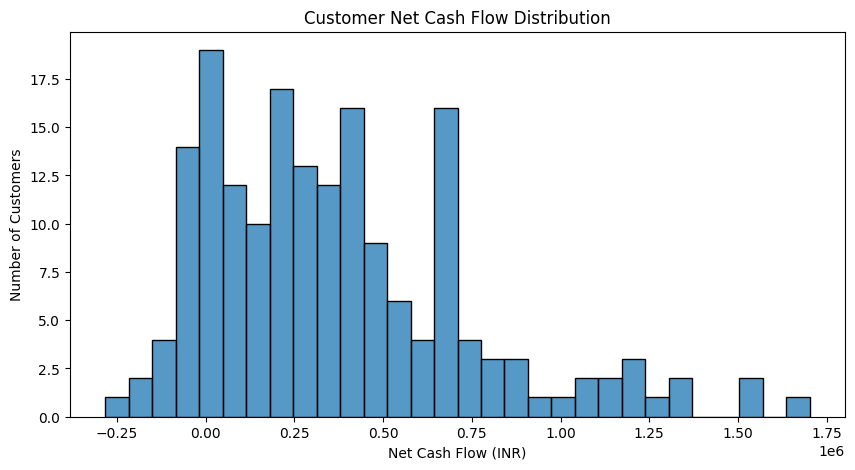

In [22]:
plt.figure(figsize=(10, 5))
sns.histplot(data=customer_financial_summary, x="net_cash_flow", bins=30)
plt.title("Customer Net Cash Flow Distribution")
plt.xlabel("Net Cash Flow (INR)")
plt.ylabel("Number of Customers")
plt.show()

In [23]:
merchant_analysis = debit_transactions.groupby("merchant").agg(transaction_count=("transaction_id", "count"), total_spending=("amount", lambda x: x.abs().sum()), average_spending=("amount", lambda x: x.abs().mean())).sort_values("total_spending", ascending=False)

merchant_analysis.head(15)

,transaction_count,total_spending,average_spending
merchant,,,
Landlord Transfer,1764,39087353.30,22158.363549
Investment Platform,1596,10986449.97,6883.740583
Training Institute,1319,7780766.93,5898.989333
BigBasket,3372,7512014.66,2227.762355
MakeMyTrip,1178,6984593.70,5929.196689
Reliance Fresh,3335,6486947.37,1945.111655
DMart,3344,5561327.51,1663.076408
Electricity Board,2160,4448308.32,2059.402000
Indian Oil,2474,3653474.58,1476.748011


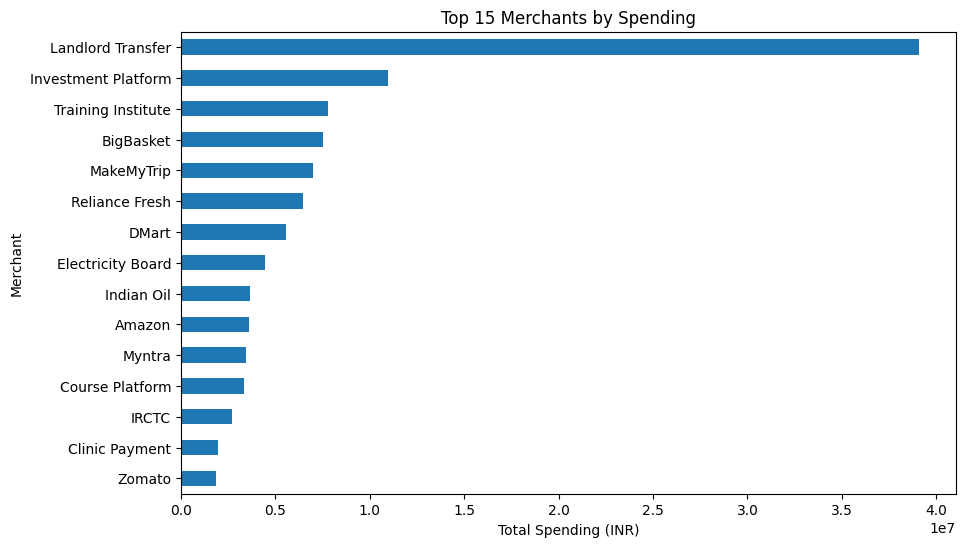

In [24]:
merchant_analysis.head(15)["total_spending"].sort_values().plot(kind="barh", figsize=(10, 6), title="Top 15 Merchants by Spending")
plt.xlabel("Total Spending (INR)")
plt.ylabel("Merchant")
plt.show()

In [25]:
daily_transactions = df.groupby("date")["transaction_id"].count()

daily_transactions.describe()

count    365.000000
mean     154.578082
std       32.591504
min      102.000000
25%      126.000000
50%      144.000000
75%      184.000000
max      242.000000
Name: transaction_id, dtype: float64

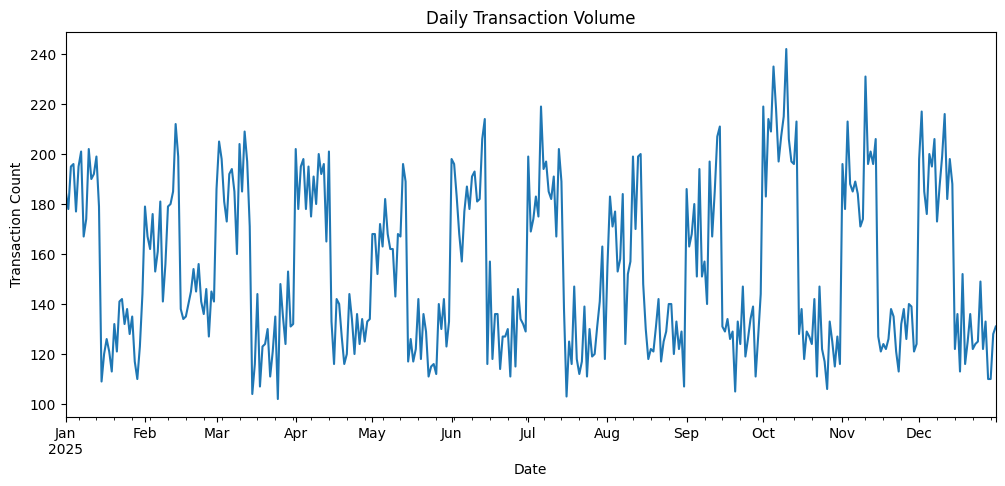

In [26]:
daily_transactions.plot(figsize=(12, 5), title="Daily Transaction Volume")
plt.xlabel("Date")
plt.ylabel("Transaction Count")
plt.show()

In [27]:
weekday_analysis = df.groupby("day_of_week")["transaction_id"].count()

weekday_analysis

day_of_week
Friday       8064
Monday       8179
Saturday     7965
Sunday       7842
Thursday     8156
Tuesday      8091
Wednesday    8124
Name: transaction_id, dtype: int64

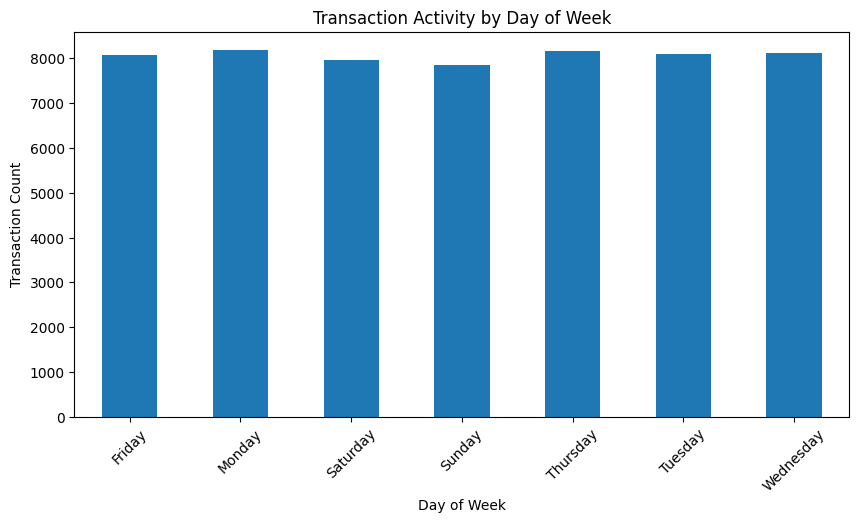

In [28]:
weekday_analysis.plot(kind="bar", figsize=(10, 5), title="Transaction Activity by Day of Week", rot=45)
plt.xlabel("Day of Week")
plt.ylabel("Transaction Count")
plt.show()

In [29]:
df.groupby("is_weekend")["transaction_id"].count()

is_weekend
False    40614
True     15807
Name: transaction_id, dtype: int64

In [30]:
customer_category_spending = debit_transactions.pivot_table(index="customer_id", columns="category", values="amount", aggfunc=lambda x: x.abs().sum(), fill_value=0)

customer_category_spending.head()

category,Bills & Utilities,Education,Entertainment,Food & Dining,Groceries,Healthcare,Housing,Investment,Personal Care,Shopping,Transport,Travel
customer_id,,,,,,,,,,,,
CUST0001,36852.97,122587.56,2002.03,15726.41,197351.08,26272.24,416253.82,77040.74,7714.65,60196.73,21606.25,35911.27
CUST0002,38059.54,76312.34,4284.24,12314.16,151277.42,29339.56,207459.90,109524.68,4888.77,39568.22,12542.04,52183.56
CUST0003,23423.94,101574.44,9149.42,27815.96,88732.84,27989.04,136928.19,0.00,8572.02,56195.43,39533.93,58825.79
CUST0004,49464.65,222977.90,6385.10,17909.60,167045.79,40793.13,343942.01,99964.06,5469.50,61341.84,29387.13,40754.90
CUST0005,54462.69,37201.98,10868.11,44275.24,109194.59,10808.03,327893.92,87769.64,17463.29,114240.41,29195.14,106430.83


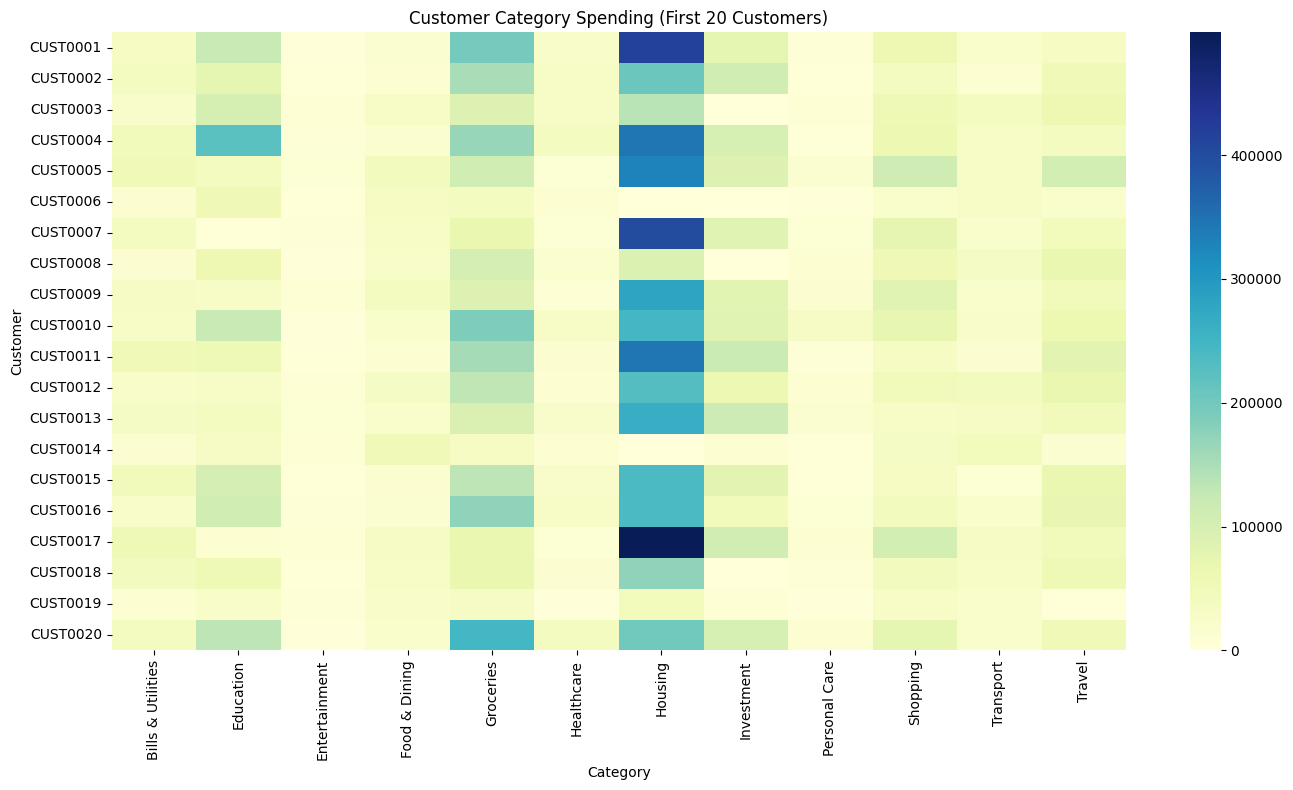

In [32]:
plt.figure(figsize=(14, 8))
sns.heatmap(customer_category_spending.head(20), cmap="YlGnBu")
plt.title("Customer Category Spending (First 20 Customers)")
plt.xlabel("Category")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()